# DS701 Midterm — Bank Marketing Dataset


## Setup — fixed seed and data loading

In [1]:
import math, json, os, platform, random, runpy, zipfile
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import sklearn
from IPython.display import display, Image
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
BASE = Path.cwd().resolve()
OUT = BASE / 'reproducibility_outputs'
OUT.mkdir(exist_ok=True)
Q1_OUT = OUT / 'q1_results'
Q1_OUT.mkdir(exist_ok=True)
# Pinned to a specific GitHub commit, rather than a changing 'main' branch.
REPO_COMMIT = '1fbd0dfe64f07fd7a9deb90f7f7eda3866381a1c'
RAW = f'https://raw.githubusercontent.com/ziqing05/DS701-midterm/{REPO_COMMIT}/'

def get_repo_file(repo_path, dest):
    dest = Path(dest)
    dest.parent.mkdir(parents=True, exist_ok=True)
    if not dest.is_file():
        print('Downloading', repo_path)
        urlretrieve(RAW + repo_path, dest)
    return dest

csv_path = get_repo_file('bank-additional-full.csv', BASE / 'bank-additional-full.csv')
df = pd.read_csv(csv_path, sep=';')
assert df.shape == (41188, 21), f'Wrong dataset version or delimiter: {df.shape}'
assert set(df['y'].unique()) == {'yes', 'no'}
print('Dataset:', csv_path, df.shape)
print('Versions:', {'python': platform.python_version(), 'numpy': np.__version__,
                    'pandas': pd.__version__, 'sklearn': sklearn.__version__})
display(df.head())

Dataset: /content/bank-additional-full.csv (41188, 21)
Versions: {'python': '3.13.18', 'numpy': '2.4.6', 'pandas': '2.2.3', 'sklearn': '1.6.1'}


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


# Q1 — Ranking Clients Before a Call

**Question:** Can we rank later-period clients before dialing to capture more subscribers than random selection within the same contact budget?

This section reproduces the methodology in `Question_Analysis.ipynb`, replacing only its interactive Google Colab CSV upload and export paths with reproducible local file paths.

## Q1.1 — Define pre-call inputs

In [2]:
X = df.drop(columns=['y', 'duration', 'campaign']).copy()
y = df['y'].eq('yes').astype(int).to_numpy()
row_ids = np.arange(len(df))
categorical_columns = X.select_dtypes(include='object').columns.tolist()
numerical_columns = X.select_dtypes(include='number').columns.tolist()
print('Number of input features:', X.shape[1])
print('Categorical features:', categorical_columns)
print('Numerical features:', numerical_columns)

Number of input features: 18
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numerical features: ['age', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


## Q1.2 — Chronological split

In [3]:
train_ids = row_ids[:24712]
validation_ids = row_ids[24712:32950]
development_ids = row_ids[:32950]
time_test_ids = row_ids[32950:]
assert not set(development_ids).intersection(time_test_ids)
display(pd.DataFrame([
 {'set':'Training','first_row':1,'last_row':24712,'n':len(train_ids)},
 {'set':'Validation','first_row':24713,'last_row':32950,'n':len(validation_ids)},
 {'set':'Time test','first_row':32951,'last_row':len(df),'n':len(time_test_ids)}]))

,set,first_row,last_row,n
0,Training,1,24712,24712
1,Validation,24713,32950,8238
2,Time test,32951,41188,8238


## Q1.3 — Ranking metric and models

In [4]:
def ranking_metrics(ids, scores):
    ids = np.asarray(ids)
    scores = np.asarray(scores)
    labels = y[ids]
    order = np.lexsort((ids, -scores))
    contact_count = math.ceil(0.10 * len(ids))
    captured = int(labels[order[:contact_count]].sum())
    subscribers = int(labels.sum())
    prevalence = float(labels.mean())
    precision = captured / contact_count
    return {
        'n': len(ids), 'subscribers': subscribers,
        'subscription_rate': prevalence, 'contacted': contact_count,
        'captured': captured, 'precision_at_10': precision,
        'recall_at_10': captured / subscribers if subscribers else np.nan,
        'lift_at_10': precision / prevalence if prevalence else np.nan,
        'random_expected_captured': contact_count * prevalence,
    }

MODEL_NAMES = ['Logistic regression', 'Random forest depth 5', 'Random forest depth 10']
def make_model(name):
    preprocessing = ColumnTransformer([
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_columns),
        ('numerical', StandardScaler(), numerical_columns),
    ])
    if name == 'Logistic regression':
        estimator = LogisticRegression(C=1, max_iter=2000, random_state=SEED)
    else:
        depth = int(name.split()[-1])
        estimator = RandomForestClassifier(
            n_estimators=200, max_depth=depth, min_samples_leaf=20,
            random_state=SEED, n_jobs=2)
    return Pipeline([('preprocessing', preprocessing), ('model', estimator)])

## Q1.4 — Model selection on validation data

In [5]:
validation_rows = []
fitted_candidates = {}
for name in MODEL_NAMES:
    pipeline = make_model(name)
    pipeline.fit(X.iloc[train_ids], y[train_ids])
    scores = pipeline.predict_proba(X.iloc[validation_ids])[:, 1]
    validation_rows.append({'model': name, **ranking_metrics(validation_ids, scores)})
    fitted_candidates[name] = pipeline
validation_results = pd.DataFrame(validation_rows)
selected_name = max(validation_rows, key=lambda row: row['lift_at_10'])['model']
display(validation_results)
print('Selected model:', selected_name)

,model,n,subscribers,subscription_rate,contacted,captured,precision_at_10,recall_at_10,lift_at_10,random_expected_captured
0,Logistic regression,8238,912,0.110706,824,42,0.050971,0.046053,0.460415,91.222141
1,Random forest depth 5,8238,912,0.110706,824,111,0.134709,0.121711,1.216810,91.222141
2,Random forest depth 10,8238,912,0.110706,824,102,0.123786,0.111842,1.118150,91.222141


Selected model: Random forest depth 5


## Q1.5 — Validation stability

In [6]:
selected_training_model = fitted_candidates[selected_name]
stability_rows = []
for label, ids in [
    ('Earlier validation half', validation_ids[:4119]),
    ('Later validation half', validation_ids[4119:]),
]:
    scores = selected_training_model.predict_proba(X.iloc[ids])[:, 1]
    stability_rows.append({'period': label, **ranking_metrics(ids, scores)})
stability_results = pd.DataFrame(stability_rows)
display(stability_results)

,period,n,subscribers,subscription_rate,contacted,captured,precision_at_10,recall_at_10,lift_at_10,random_expected_captured
0,Earlier validation half,4119,418,0.101481,412,45,0.109223,0.107656,1.076294,41.810148
1,Later validation half,4119,494,0.119932,412,69,0.167476,0.139676,1.396422,49.411993


## Q1.6 — Random split comparison

In [7]:
random_development_ids, random_test_ids = train_test_split(
    row_ids, test_size=0.2, random_state=SEED, stratify=y)
assert not set(random_development_ids).intersection(random_test_ids)
print('Random development size:', len(random_development_ids))
print('Random test size:', len(random_test_ids))

Random development size: 32950
Random test size: 8238


## Q1.7 — Final evaluation

In [8]:
test_rows = []
prediction_frames = []
for split_name, fit_ids, test_ids in [
    ('Time-based', development_ids, time_test_ids),
    ('Random', random_development_ids, random_test_ids),
]:
    final_model = make_model(selected_name)
    final_model.fit(X.iloc[fit_ids], y[fit_ids])
    scores = final_model.predict_proba(X.iloc[test_ids])[:, 1]
    test_rows.append({
        'split': split_name, 'model': selected_name,
        **ranking_metrics(test_ids, scores),
    })
    prediction_frames.append(pd.DataFrame({
        'split': split_name, 'original_row': test_ids + 1,
        'actual_yes': y[test_ids], 'score': scores,
    }))
test_results = pd.DataFrame(test_rows)
test_predictions = pd.concat(prediction_frames, ignore_index=True)
display(test_results)

,split,model,n,subscribers,subscription_rate,contacted,captured,precision_at_10,recall_at_10,lift_at_10,random_expected_captured
0,Time-based,Random forest depth 5,8238,2540,0.308327,824,487,0.591019,0.191732,1.916857,254.061665
1,Random,Random forest depth 5,8238,928,0.112649,824,414,0.502427,0.446121,4.460124,92.822530


## Q1.8 — Interpretation and exports

In [9]:
for result in test_rows:
    print(f"{result['split']} test")
    print(f"  Selected model: {selected_name}")
    print(f"  Overall subscription rate: {result['subscription_rate']:.2%}")
    print(f"  Clients contacted: {result['contacted']:,}")
    print(f"  Actual subscribers captured: {result['captured']:,}")
    print(f"  Random expected capture: {result['random_expected_captured']:.2f}")
    print(f"  Precision@10%: {result['precision_at_10']:.2%}")
    print(f"  Recall@10%: {result['recall_at_10']:.2%}")
    print(f"  Lift@10%: {result['lift_at_10']:.3f}")
    print()
validation_results.to_csv(Q1_OUT / 'validation_results.csv', index=False)
stability_results.to_csv(Q1_OUT / 'stability_results.csv', index=False)
test_results.to_csv(Q1_OUT / 'test_results.csv', index=False)
test_predictions.to_csv(Q1_OUT / 'test_predictions.csv', index=False)
manifest = pd.DataFrame({
    'original_row': row_ids + 1,
    'time_split': np.where(row_ids < 24712, 'training',
                           np.where(row_ids < 32950, 'validation', 'test')),
    'random_split': 'development',
})
manifest.loc[random_test_ids, 'random_split'] = 'test'
manifest.to_csv(Q1_OUT / 'split_manifest.csv', index=False)
metadata = {
    'selected_model': selected_name,
    'excluded_columns': ['y', 'duration', 'campaign'],
    'seed': SEED, 'contact_fraction': 0.10,
    'versions': {'python': platform.python_version(), 'sklearn': sklearn.__version__,
                 'pandas': pd.__version__, 'numpy': np.__version__},
}
(Q1_OUT / 'metadata.json').write_text(json.dumps(metadata, indent=2))
print('Q1 outputs saved to:', Q1_OUT)

Time-based test
  Selected model: Random forest depth 5
  Overall subscription rate: 30.83%
  Clients contacted: 824
  Actual subscribers captured: 487
  Random expected capture: 254.06
  Precision@10%: 59.10%
  Recall@10%: 19.17%
  Lift@10%: 1.917

Random test
  Selected model: Random forest depth 5
  Overall subscription rate: 11.26%
  Clients contacted: 824
  Actual subscribers captured: 414
  Random expected capture: 92.82
  Precision@10%: 50.24%
  Recall@10%: 44.61%
  Lift@10%: 4.460

Q1 outputs saved to: /content/reproducibility_outputs/q1_results


# Q3 — SVD & Clustering (master_pipeline.py)

Full original Python code from `svd_analysis/master_pipeline.py` is embedded below, unchanged. No Q3 Python script download or import is required. The setup below only gives the original script its expected `__file__` path, allowing the existing data and output paths to work.

In [10]:
# Notebook-only path setup; this is not part of master_pipeline.py.
# The original script resolves its CSV and output directory relative to __file__.
Q3_DIR = BASE / 'svd_analysis'
Q3_DIR.mkdir(parents=True, exist_ok=True)
__file__ = str(Q3_DIR / 'master_pipeline.py')
print('Q3 working directory:', Q3_DIR)
print('Dataset:', BASE / 'bank-additional-full.csv')

Q3 working directory: /content/svd_analysis
Dataset: /content/bank-additional-full.csv


In [11]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, cophenet
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import KFold

def main():
    script_dir = os.path.dirname(os.path.abspath(__file__))
    data_path = os.path.join(script_dir, '..', 'bank-additional-full.csv')
    df = pd.read_csv(data_path, sep=';')

    train_df = df.iloc[:24712].copy()

    tier_map = {
        'admin.': 'White-Collar', 'technician': 'White-Collar', 'management': 'White-Collar',
        'blue-collar': 'Blue-Collar/Services', 'services': 'Blue-Collar/Services', 'housemaid': 'Blue-Collar/Services',
        'entrepreneur': 'Independent/Biz', 'self-employed': 'Independent/Biz',
        'retired': 'Life-Stage', 'student': 'Life-Stage', 'unemployed': 'Life-Stage',
        'unknown': 'Other'
    }
    train_df['job_tier'] = train_df['job'].map(tier_map)
    tiers = ['White-Collar', 'Blue-Collar/Services', 'Independent/Biz', 'Life-Stage']

    num_cols = ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
    cat_cols = ['marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
    feature_cols = num_cols + cat_cols

    base_rate = (train_df['y'] == 'yes').mean()
    print("=" * 80)
    print("DS701 MIDTERM: MASTER SVD & CLUSTERING PIPELINE")
    print(f"Training Rows: {len(train_df):,} | Base Conversion Rate: {base_rate*100:.2f}%")
    print("=" * 80)


    print("\n[STAGE 1] Running SVD Dimensionality Sweep (k in [2, 3, 5, 8, 10, 15, 20, 30])...")

    full_pipe = ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), cat_cols)
    ])
    X_full = full_pipe.fit_transform(train_df[feature_cols])
    X_mean = np.mean(X_full, axis=0)
    X_centered = X_full - X_mean

    total_variance = np.sum(np.var(X_centered, axis=0))
    frobenius_full = np.linalg.norm(X_centered, 'fro')

    np.random.seed(42)
    sample_idx = np.random.choice(len(X_centered), size=1200, replace=False)
    X_sub = X_centered[sample_idx]
    dist_raw = pdist(X_sub)
    Z_raw_ward = linkage(X_sub, method='ward')
    c_raw, _ = cophenet(Z_raw_ward, dist_raw)

    svd_k_list = [2, 3, 5, 8, 10, 15, 20, 30]
    svd_records = []

    for k in svd_k_list:
        svd = TruncatedSVD(n_components=k, random_state=42)
        Z_k = svd.fit_transform(X_centered)
        X_rec = svd.inverse_transform(Z_k)

        var_expl = np.sum(svd.explained_variance_)
        var_ratio = var_expl / total_variance
        recon_err = np.linalg.norm(X_centered - X_rec, 'fro') / frobenius_full

        Z_sub = Z_k[sample_idx]
        c_k, _ = cophenet(linkage(Z_sub, method='ward'), pdist(Z_sub))

        svd_records.append({
            'k': k,
            'variance_explained_ratio': var_ratio,
            'frobenius_relative_error': recon_err,
            'cophenetic_corr': c_k
        })
        print(f"  k={k:2d} | Variance Expl={var_ratio*100:.1f}% | Rel Error={recon_err*100:.1f}% | Cophenetic Corr={c_k:.3f}")

    svd_df = pd.DataFrame(svd_records)
    svd_df.to_csv(os.path.join(script_dir, 'master_svd_sweep.csv'), index=False)


    print("\n[STAGE 2] Running 5-Fold CV Clustering Sweep (k=5 SVD, K in [4, 6, 8, 10, 12, 15, 20])...")

    k_clusters_list = [4, 6, 8, 10, 12, 15, 20]
    methods = ['Dendrogram (Ward)', 'KMeans']
    kf = KFold(n_splits=5, shuffle=True, random_state=42)

    clustering_results = []
    oof_predictions_store = {}

    for method in methods:
        print(f"\n  Evaluating {method}:")
        for K in k_clusters_list:
            oof_tier_preds = []
            oof_tier_actuals = []
            oof_edu_preds = []
            oof_house_preds = []
            oof_cluster_ids = []
            oof_cluster_conv_rates = []
            oof_indices = []

            for train_idx, val_idx in kf.split(train_df):
                tr = train_df.iloc[train_idx]
                va = train_df.iloc[val_idx]

                pipe = ColumnTransformer([
                    ('num', StandardScaler(), num_cols),
                    ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), cat_cols)
                ])
                X_tr = pipe.fit_transform(tr[feature_cols])
                X_va = pipe.transform(va[feature_cols])

                m_tr = np.mean(X_tr, axis=0)
                X_tr_c = X_tr - m_tr
                X_va_c = X_va - m_tr

                # SVD k=5
                svd = TruncatedSVD(n_components=5, random_state=42)
                Z_tr = svd.fit_transform(X_tr_c)
                Z_va = svd.transform(X_va_c)

                if method == 'Dendrogram (Ward)':
                    model = AgglomerativeClustering(n_clusters=K, linkage='ward')
                    tr_labels = model.fit_predict(Z_tr)

                    centroids = np.zeros((K, Z_tr.shape[1]))
                    for c in range(K):
                        mask = (tr_labels == c)
                        if mask.sum() > 0:
                            centroids[c] = np.mean(Z_tr[mask], axis=0)

                    dists = np.linalg.norm(Z_va[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2)
                    va_labels = np.argmin(dists, axis=1)
                else:
                    model = KMeans(n_clusters=K, random_state=42, n_init=10).fit(Z_tr)
                    tr_labels = model.labels_
                    va_labels = model.predict(Z_va)

                # Prevalence-Lift Assignment for Job Tier & Secondary Features
                base_p = tr['job_tier'].value_counts(normalize=True)
                base_edu = tr['education'].value_counts(normalize=True)

                c_tier_pred = {}
                c_edu_pred = {}
                c_house_pred = {}
                c_conv_rate = {}

                for c in range(K):
                    mask = (tr_labels == c)
                    if mask.sum() == 0:
                        c_tier_pred[c] = 'White-Collar'
                        c_edu_pred[c] = 'university.degree'
                        c_house_pred[c] = 'yes'
                        c_conv_rate[c] = base_rate
                        continue

                    c_p = tr.iloc[mask]['job_tier'].value_counts(normalize=True)
                    lifts = {t: c_p.get(t, 0.0) / base_p.get(t, 1e-6) for t in tiers}
                    c_tier_pred[c] = max(lifts, key=lifts.get)

                    c_edu_p = tr.iloc[mask]['education'].value_counts(normalize=True)
                    edu_lifts = {e: c_edu_p.get(e, 0.0) / base_edu.get(e, 1e-6) for e in base_edu.index}
                    c_edu_pred[c] = max(edu_lifts, key=edu_lifts.get)

                    c_house_pred[c] = tr.iloc[mask]['housing'].mode()[0]

                    c_conv_rate[c] = (tr.iloc[mask]['y'] == 'yes').mean()

                oof_tier_preds.extend([c_tier_pred[c] for c in va_labels])
                oof_tier_actuals.extend(va['job_tier'].tolist())
                oof_edu_preds.extend([c_edu_pred[c] for c in va_labels])
                oof_house_preds.extend([c_house_pred[c] for c in va_labels])
                oof_cluster_ids.extend(va_labels.tolist())
                oof_cluster_conv_rates.extend([c_conv_rate[c] for c in va_labels])
                oof_indices.extend(val_idx.tolist())

            oof_tier_preds = np.array(oof_tier_preds)
            oof_tier_actuals = np.array(oof_tier_actuals)

            acc = accuracy_score(oof_tier_actuals, oof_tier_preds)
            macro_f1 = f1_score(oof_tier_actuals, oof_tier_preds, average='macro', zero_division=0)

            tier_recalls = {}
            for t in tiers:
                t_mask = (oof_tier_actuals == t)
                tier_recalls[t] = np.mean(oof_tier_preds[t_mask] == t) if t_mask.sum() > 0 else 0.0

            edu_f1 = f1_score(train_df.iloc[oof_indices]['education'], oof_edu_preds, average='macro', zero_division=0)
            house_f1 = f1_score(train_df.iloc[oof_indices]['housing'], oof_house_preds, average='macro', zero_division=0)

            clustering_results.append({
                'Method': method,
                'K': K,
                'Accuracy': acc,
                'Macro_F1': macro_f1,
                'Tiers_Predicted': len(set(oof_tier_preds)),
                'Recall_White_Collar': tier_recalls['White-Collar'],
                'Recall_Blue_Collar': tier_recalls['Blue-Collar/Services'],
                'Recall_Ind_Biz': tier_recalls['Independent/Biz'],
                'Recall_Life_Stage': tier_recalls['Life-Stage'],
                'Edu_Macro_F1': edu_f1,
                'House_Macro_F1': house_f1
            })

            oof_predictions_store[(method, K)] = pd.DataFrame({
                'idx': oof_indices,
                'pred_tier': oof_tier_preds,
                'actual_tier': oof_tier_actuals,
                'cluster_rate': oof_cluster_conv_rates,
                'y': (train_df.iloc[oof_indices]['y'] == 'yes').astype(int).values
            })

            print(f"    K={K:2d} | Macro F1={macro_f1:.4f} | Life-Stage Recall={tier_recalls['Life-Stage']*100:.1f}% | Ind/Biz Recall={tier_recalls['Independent/Biz']*100:.1f}%")

    clustering_df = pd.DataFrame(clustering_results)
    clustering_df.to_csv(os.path.join(script_dir, 'master_clustering_sweep.csv'), index=False)

#CBA
    print("\n[STAGE 3] Performing Cost-Benefit Analysis (CBA)...")
    print("  Parameters: Call Cost = $5.00 | Conversion Value = $100.00")

    call_cost = 5.0
    conversion_value = 100.0
    budget_target = 150

    cba_records = []

    rand_exp_conv = budget_target * base_rate
    rand_cost = budget_target * call_cost
    rand_rev = rand_exp_conv * conversion_value
    rand_profit = rand_rev - rand_cost
    rand_roi = (rand_profit / rand_cost) * 100

    cba_records.append({
        'Model': 'Random Selection',
        'K': '-',
        'Calls': budget_target,
        'Conversions': rand_exp_conv,
        'Conversion_Rate': base_rate,
        'Lift': 1.0,
        'Total_Cost': rand_cost,
        'Gross_Revenue': rand_rev,
        'Net_Profit': rand_profit,
        'ROI_Pct': rand_roi,
        'Net_Benefit_vs_Random': 0.0
    })

    for method in ['Dendrogram (Ward)', 'KMeans']:
        for K in [8, 10, 15, 20]:
            df_pred = oof_predictions_store[(method, K)].sort_values(by='cluster_rate', ascending=False)
            top_cohort = df_pred.iloc[:budget_target]

            act_conv = top_cohort['y'].sum()
            act_rate = top_cohort['y'].mean()
            lift = act_rate / base_rate

            cost = budget_target * call_cost
            rev = act_conv * conversion_value
            profit = rev - cost
            roi = (profit / cost) * 100
            net_benefit = profit - rand_profit

            cba_records.append({
                'Model': method,
                'K': K,
                'Calls': budget_target,
                'Conversions': act_conv,
                'Conversion_Rate': act_rate,
                'Lift': lift,
                'Total_Cost': cost,
                'Gross_Revenue': rev,
                'Net_Profit': profit,
                'ROI_Pct': roi,
                'Net_Benefit_vs_Random': net_benefit
            })

    cba_df = pd.DataFrame(cba_records)
    cba_df.to_csv(os.path.join(script_dir, 'master_cba_summary.csv'), index=False)

    print("\nCBA Summary Table (Top 150 Calls @ $5/call, $100/conversion):")
    print(cba_df[['Model', 'K', 'Conversions', 'Conversion_Rate', 'Net_Profit', 'ROI_Pct', 'Net_Benefit_vs_Random']].to_string(index=False))


    print("\n[STAGE 4] Generating Master 4-Panel Visualization Dashboard...")

    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(18, 13))


    ax1_twin = ax1.twinx()
    l1 = ax1.plot(svd_df['k'], svd_df['variance_explained_ratio'] * 100, marker='o', color='#2b6cb0', linewidth=2.5, label='Cumulative Variance Explained (%)')
    l2 = ax1_twin.plot(svd_df['k'], svd_df['cophenetic_corr'], marker='^', color='#38a169', linewidth=2.5, linestyle='--', label='Cophenetic Tree Correlation')
    ax1_twin.axhline(c_raw, color='gray', linestyle=':', label=f'Raw 58-D Cophenetic Baseline ({c_raw:.3f})')

    ax1.axvline(5, color='#e53e3e', linestyle='-.', alpha=0.8, label='Selected Sweet Spot (k=5)')
    ax1.set_xlabel('SVD Latent Rank (k)', fontsize=11)
    ax1.set_ylabel('Variance Explained (%)', fontsize=11, color='#2b6cb0')
    ax1_twin.set_ylabel('Cophenetic Tree Correlation', fontsize=11, color='#38a169')
    ax1.set_title('Panel A: SVD Regularization & Tree Fidelity', fontsize=12, fontweight='bold')

    lines = l1 + l2 + [ax1_twin.get_lines()[-1], ax1.get_lines()[-1]]
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='lower right', fontsize=9.5)
    ax1.grid(True, linestyle='--', alpha=0.5)


    dendro_res = clustering_df[clustering_df['Method'] == 'Dendrogram (Ward)']
    kmeans_res = clustering_df[clustering_df['Method'] == 'KMeans']

    ax2.plot(dendro_res['K'], dendro_res['Macro_F1'], marker='o', color='#2b6cb0', linewidth=2.5, label='Dendrogram Macro F1')
    ax2.plot(kmeans_res['K'], kmeans_res['Macro_F1'], marker='s', color='#dd6b20', linewidth=2.5, label='KMeans Macro F1')
    ax2.plot(dendro_res['K'], dendro_res['Recall_Life_Stage'], marker='D', color='#e53e3e', linewidth=2, linestyle='--', label='Life-Stage Recall (Dendrogram)')
    ax2.plot(dendro_res['K'], dendro_res['Recall_Ind_Biz'], marker='v', color='#805ad5', linewidth=2, linestyle='--', label='Ind/Biz Recall (Dendrogram)')
    ax2.axhline(0.1312, color='gray', linestyle=':', label='Majority Class Baseline F1 (0.1312)')

    ax2.set_xlabel('Number of Clusters (K)', fontsize=11)
    ax2.set_ylabel('Score / Recall', fontsize=11)
    ax2.set_title('Panel B: Multi-Tier Clustering Generalization\n', fontsize=12, fontweight='bold')
    ax2.set_xticks(k_clusters_list)
    ax2.legend(loc='lower right', fontsize=9.5)
    ax2.grid(True, linestyle='--', alpha=0.5)


    cba_subset = cba_df[cba_df['K'].isin(['-', 10, 15, 20])].copy()
    labels_cba = [f"{row['Model']}\n(K={row['K']})" if row['K'] != '-' else "Random Dialing\n(Population Base)" for _, row in cba_subset.iterrows()]
    profits = cba_subset['Net_Profit'].values
    colors = ['#e53e3e' if p < 0 else '#3182ce' if 'Dendrogram' in m else '#dd6b20' for p, m in zip(profits, cba_subset['Model'])]

    bars = ax3.bar(range(len(profits)), profits, color=colors, width=0.55)
    ax3.axhline(0, color='black', linewidth=1)
    ax3.set_ylabel('Net Profit ($) for 150 Calls', fontsize=11)
    ax3.set_title('Panel C: Cost-Benefit Analysis (Top 150 Leads)\nCost=$5/call, Revenue=$100/conversion', fontsize=12, fontweight='bold')
    ax3.set_xticks(range(len(profits)))
    ax3.set_xticklabels(labels_cba, rotation=15, ha='right', fontsize=9)
    ax3.grid(axis='y', linestyle='--', alpha=0.5)

    for bar, p, conv, roi in zip(bars, profits, cba_subset['Conversions'], cba_subset['ROI_Pct']):
        y_pos = bar.get_height()
        if p >= 0:
            ax3.text(bar.get_x() + bar.get_width()/2.0, y_pos + 80, f"+${p:,.0f}\n({conv:.0f} conv, {roi:.0f}% ROI)", ha='center', va='bottom', fontsize=8.5, fontweight='bold')
        else:
            ax3.text(bar.get_x() + bar.get_width()/2.0, y_pos - 350, f"-${abs(p):,.0f}\n({conv:.1f} conv, {roi:.1f}% ROI)", ha='center', va='top', fontsize=8.5, fontweight='bold', color='crimson')


    budgets = np.arange(25, 601, 25)
    dendro10_df = oof_predictions_store[('Dendrogram (Ward)', 10)].sort_values(by='cluster_rate', ascending=False)
    dendro15_df = oof_predictions_store[('Dendrogram (Ward)', 15)].sort_values(by='cluster_rate', ascending=False)

    profit_rand_curve = (budgets * base_rate * conversion_value) - (budgets * call_cost)
    profit_d10_curve = [dendro10_df.iloc[:b]['y'].sum() * conversion_value - (b * call_cost) for b in budgets]
    profit_d15_curve = [dendro15_df.iloc[:b]['y'].sum() * conversion_value - (b * call_cost) for b in budgets]

    ax4.plot(budgets, profit_d15_curve, marker='D', color='#38a169', linewidth=2.5, label='Dendrogram (K=15) Prioritization')
    ax4.plot(budgets, profit_d10_curve, marker='o', color='#2b6cb0', linewidth=2.5, label='Dendrogram (K=10) Prioritization')
    ax4.plot(budgets, profit_rand_curve, color='#e53e3e', linestyle='--', linewidth=2, label='Random Selection (Negative ROI Baseline)')
    ax4.axhline(0, color='black', linewidth=0.8, linestyle=':')

    ax4.set_xlabel('Call Volume Budget (Number of Calls Made)', fontsize=11)
    ax4.set_ylabel('Net Profit ($)', fontsize=11)
    ax4.set_title('Panel D: Cumulative Net Profit vs. Contact Budget Curve\n', fontsize=12, fontweight='bold')
    ax4.legend(loc='upper left', fontsize=10)
    ax4.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    dashboard_path = os.path.join(script_dir, 'master_pipeline_dashboard.png')
    fig.savefig(dashboard_path, dpi=200)
    plt.close()
    print(f"\n[DONE] Saved consolidated visual dashboard to: {dashboard_path}")
    print("=" * 80)

if __name__ == '__main__':
    main()


DS701 MIDTERM: MASTER SVD & CLUSTERING PIPELINE
Training Rows: 24,712 | Base Conversion Rate: 4.81%

[STAGE 1] Running SVD Dimensionality Sweep (k in [2, 3, 5, 8, 10, 15, 20, 30])...
  k= 2 | Variance Expl=34.4% | Rel Error=81.0% | Cophenetic Corr=0.769
  k= 3 | Variance Expl=45.9% | Rel Error=73.5% | Cophenetic Corr=0.754
  k= 5 | Variance Expl=61.4% | Rel Error=62.2% | Cophenetic Corr=0.669
  k= 8 | Variance Expl=76.7% | Rel Error=48.3% | Cophenetic Corr=0.566
  k=10 | Variance Expl=82.1% | Rel Error=42.4% | Cophenetic Corr=0.553
  k=15 | Variance Expl=90.9% | Rel Error=30.1% | Cophenetic Corr=0.527
  k=20 | Variance Expl=97.0% | Rel Error=17.4% | Cophenetic Corr=0.512
  k=30 | Variance Expl=100.0% | Rel Error=0.0% | Cophenetic Corr=0.508

[STAGE 2] Running 5-Fold CV Clustering Sweep (k=5 SVD, K in [4, 6, 8, 10, 12, 15, 20])...

  Evaluating Dendrogram (Ward):
    K= 4 | Macro F1=0.2169 | Life-Stage Recall=0.0% | Ind/Biz Recall=5.5%
    K= 6 | Macro F1=0.2322 | Life-Stage Recall=7.8%

## Q3 results and dashboard

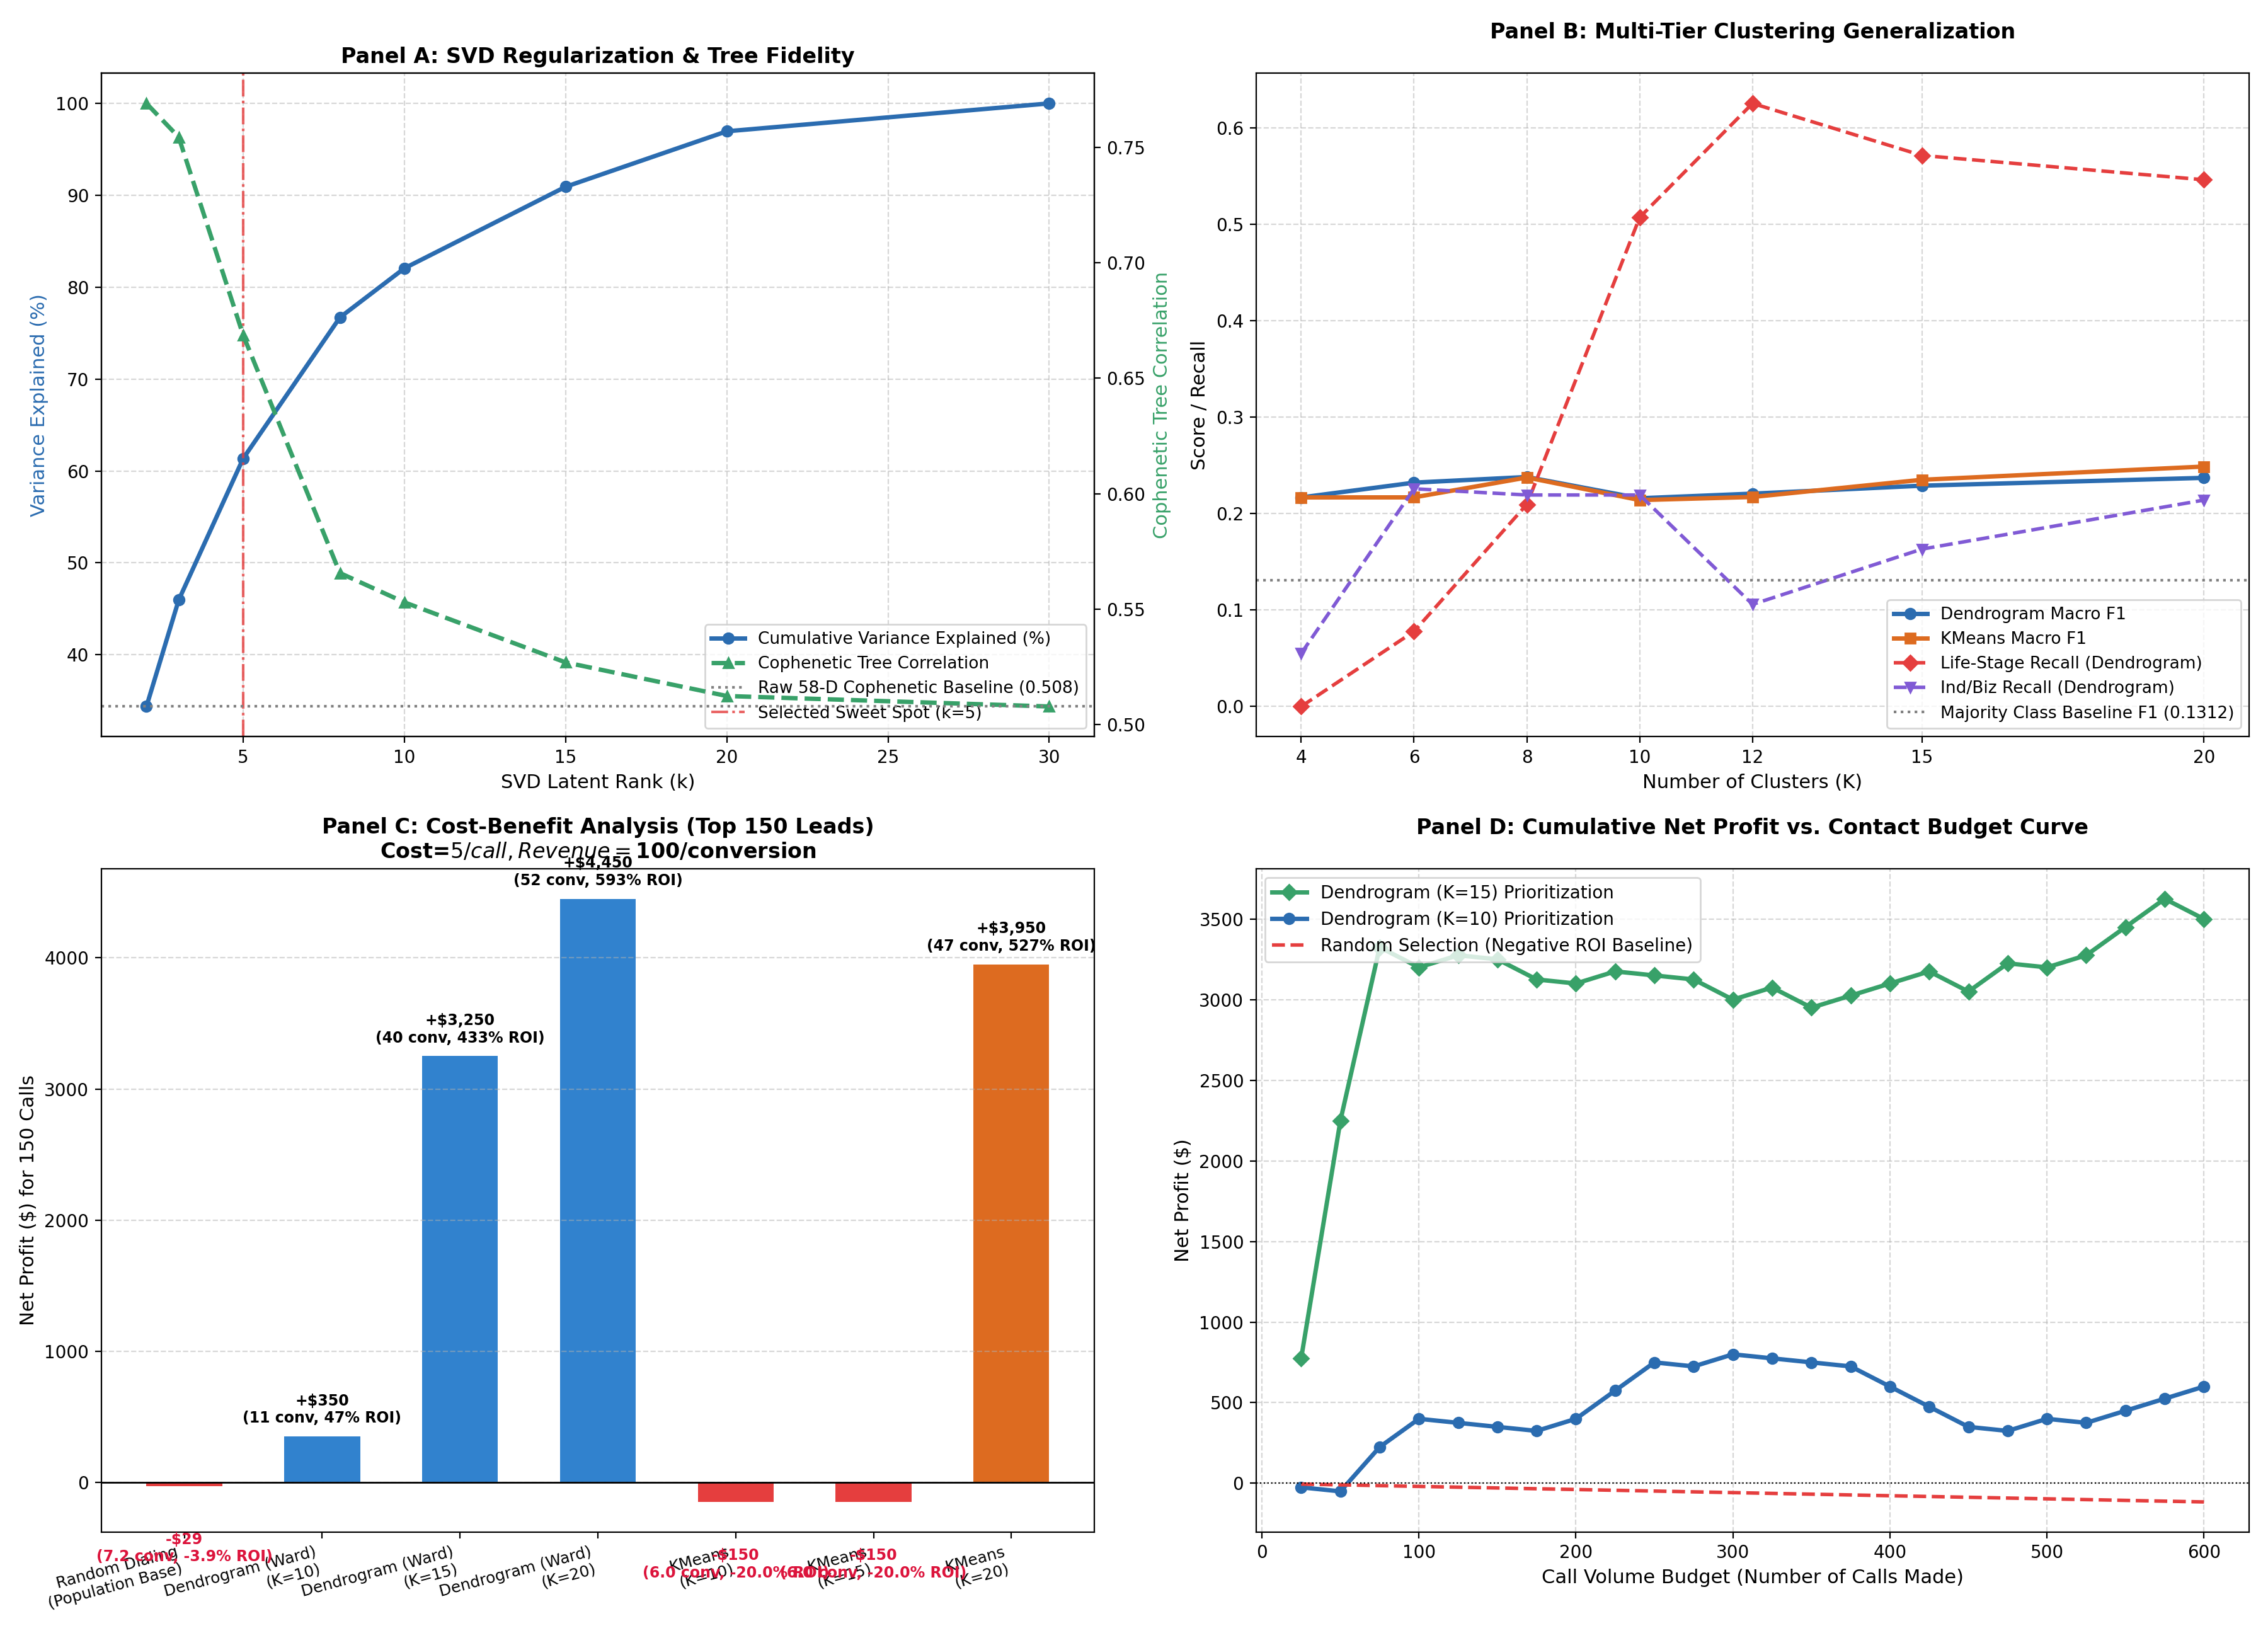


 master_svd_sweep.csv


,k,variance_explained_ratio,frobenius_relative_error,cophenetic_corr
0,2,0.343663,0.810146,0.769089
1,3,0.459484,0.735198,0.754488
2,5,0.613551,0.621650,0.668679
3,8,0.767038,0.482662,0.565629
4,10,0.820546,0.423620,0.552934
5,15,0.909252,0.301244,0.526912
6,20,0.969647,0.174220,0.512354
7,30,1.000000,0.000006,0.507809



 master_clustering_sweep.csv


,Method,K,Accuracy,Macro_F1,Tiers_Predicted,Recall_White_Collar,Recall_Blue_Collar,Recall_Ind_Biz,Recall_Life_Stage,Edu_Macro_F1,House_Macro_F1
0,Dendrogram (Ward),4,0.481386,0.216897,3,0.305275,0.879467,0.055003,0.000000,0.078155,0.326391
1,Dendrogram (Ward),6,0.414050,0.232245,4,0.305275,0.655296,0.225863,0.077869,0.093801,0.359923
2,Dendrogram (Ward),8,0.394302,0.238097,4,0.305275,0.582738,0.219427,0.209699,0.114778,0.358748
3,Dendrogram (Ward),10,0.321504,0.216019,4,0.217034,0.455924,0.219427,0.507514,0.140055,0.358748
4,Dendrogram (Ward),12,0.344205,0.220821,4,0.217034,0.518952,0.105910,0.625683,0.141313,0.359728
5,Dendrogram (Ward),15,0.355010,0.229069,4,0.217034,0.545809,0.163253,0.571721,0.138814,0.359427
6,Dendrogram (Ward),20,0.362051,0.237198,4,0.224581,0.549383,0.214160,0.546448,0.161703,0.358894
7,KMeans,4,0.481386,0.216895,3,0.305275,0.879467,0.055003,0.000000,0.078172,0.326369
8,KMeans,6,0.417449,0.216961,3,0.305275,0.668399,0.270919,0.000000,0.084283,0.360257
9,KMeans,8,0.397499,0.237604,4,0.305275,0.594542,0.173201,0.243169,0.115006,0.360135



 master_cba_summary.csv


,Model,K,Calls,Conversions,Conversion_Rate,Lift,Total_Cost,Gross_Revenue,Net_Profit,ROI_Pct,Net_Benefit_vs_Random
0,Random Selection,-,150,7.211072,0.048074,1.000000,750.0,721.107154,-28.892846,-3.852379,0.000000
1,Dendrogram (Ward),8,150,8.000000,0.053333,1.109405,750.0,800.000000,50.000000,6.666667,78.892846
2,Dendrogram (Ward),10,150,11.000000,0.073333,1.525432,750.0,1100.000000,350.000000,46.666667,378.892846
3,Dendrogram (Ward),15,150,40.000000,0.266667,5.547026,750.0,4000.000000,3250.000000,433.333333,3278.892846
4,Dendrogram (Ward),20,150,52.000000,0.346667,7.211134,750.0,5200.000000,4450.000000,593.333333,4478.892846
5,KMeans,8,150,4.000000,0.026667,0.554703,750.0,400.000000,-350.000000,-46.666667,-321.107154
6,KMeans,10,150,6.000000,0.040000,0.832054,750.0,600.000000,-150.000000,-20.000000,-121.107154
7,KMeans,15,150,6.000000,0.040000,0.832054,750.0,600.000000,-150.000000,-20.000000,-121.107154
8,KMeans,20,150,47.000000,0.313333,6.517755,750.0,4700.000000,3950.000000,526.666667,3978.892846


In [12]:
from IPython.display import Image, display
q3_dir = BASE / 'svd_analysis'
dashboard = q3_dir / 'master_pipeline_dashboard.png'
assert dashboard.exists(), 'Q3 dashboard was not generated.'
display(Image(filename=str(dashboard), width=850))
for name in ['master_svd_sweep.csv','master_clustering_sweep.csv','master_cba_summary.csv']:
    p = q3_dir / name
    assert p.exists(), f'Missing: {p}'
    print('\n', name)
    display(pd.read_csv(p).head(15))

## Reproducibility notes

- Q1 keeps its existing analysis and selected-model validation procedure.
- Q3 is embedded verbatim; the only adaptation is a separate preceding cell that defines the original script path.
- The data loading cell downloads the dataset automatically from the pinned repository commit. The Q3 script itself is not downloaded.
- `Restart Kernel and Run All` should be tested in an environment with `numpy`, `pandas`, `scipy`, `matplotlib`, `scikit-learn`, and `IPython` installed.